In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
df = pd.read_excel("Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [77]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [78]:
print("Rows:", len(df))
print("Invoices:", df["InvoiceNo"].nunique())
print("Customers:", df["CustomerID"].nunique())

Rows: 541909
Invoices: 25900
Customers: 4372


In [79]:
# Count cancelled invoice records
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Cancelled rows:", cancelled.sum())

# Count unique cancelled invoices
print("Cancelled invoices:",
      df.loc[cancelled, "InvoiceNo"].nunique())

# Count rows with negative quantities
print("Negative quantity rows:",
      (df["Quantity"] < 0).sum())


Cancelled rows: 9288
Cancelled invoices: 3836
Negative quantity rows: 10624


In [80]:
negative = df["Quantity"] < 0

negative_without_c = negative & ~cancelled

print(negative_without_c.sum())

1336


In [81]:
df.loc[negative_without_c].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [82]:
suspicious = df.loc[negative_without_c]

print("Total rows:", len(suspicious))

print("Missing CustomerID:",
      suspicious["CustomerID"].isna().sum())

print("Zero UnitPrice:",
      (suspicious["UnitPrice"] == 0).sum())

print("Missing Description:",
      suspicious["Description"].isna().sum())

Total rows: 1336
Missing CustomerID: 1336
Zero UnitPrice: 1336
Missing Description: 862


In [83]:
df_clean = df.copy()

In [84]:
df_clean = df_clean.dropna(subset=["CustomerID"])

In [85]:
print("Rows after cleaning:", len(df_clean))

Rows after cleaning: 406829


In [86]:
df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()

8905

In [87]:

df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Remaining rows:", len(df_clean))


Remaining rows: 397924


In [88]:
print("Negative quantities:", (df_clean["Quantity"] < 0).sum())

print("Zero quantities:", (df_clean["Quantity"] == 0).sum())

print("Zero prices:", (df_clean["UnitPrice"] == 0).sum())

print("Negative prices:", (df_clean["UnitPrice"] < 0).sum())

Negative quantities: 0
Zero quantities: 0
Zero prices: 40
Negative prices: 0


In [89]:
zero_price = df_clean[df_clean["UnitPrice"] == 0]

zero_price.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [90]:
df_paid = df_clean[df_clean["UnitPrice"] > 0].copy()

print("Paid purchase rows:", len(df_paid))

Paid purchase rows: 397884


# *Customer Loyalty Analysis!*

In [91]:
df_paid["TotalPrice"] = df_paid["Quantity"] * df_paid["UnitPrice"]

df_paid.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [92]:
df_paid.groupby("CustomerID")["TotalPrice"].sum()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
             ...   
18280.0      180.60
18281.0       80.82
18282.0      178.05
18283.0     2094.88
18287.0     1837.28
Name: TotalPrice, Length: 4338, dtype: float64

In [93]:
df_paid.groupby("CustomerID")["InvoiceNo"].nunique()

CustomerID
12346.0     1
12347.0     7
12348.0     4
12349.0     1
12350.0     1
           ..
18280.0     1
18281.0     1
18282.0     2
18283.0    16
18287.0     3
Name: InvoiceNo, Length: 4338, dtype: int64

In [94]:
purchase_frequency = df_paid.groupby("CustomerID")["InvoiceNo"].nunique()

repeat_customers = (purchase_frequency > 1).sum()

print("Repeat Customers:", repeat_customers)

Repeat Customers: 2845


In [95]:
total_customers = purchase_frequency.count()

repeat_purchase_rate = (repeat_customers / total_customers) * 100

print("Repeat Purchase Rate:", round(repeat_purchase_rate, 2), "%")

Repeat Purchase Rate: 65.58 %


In [96]:
customer_spending = df_paid.groupby("CustomerID")["TotalPrice"].sum()

customer_spending.head()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
Name: TotalPrice, dtype: float64

In [97]:
customer_summary = pd.DataFrame({
    "Frequency": purchase_frequency,
    "TotalSpending": customer_spending
})

customer_summary.head()

,Frequency,TotalSpending
CustomerID,,
12346.0,1,77183.60
12347.0,7,4310.00
12348.0,4,1797.24
12349.0,1,1757.55
12350.0,1,334.40


In [98]:
customer_summary["CustomerType"] = customer_summary["Frequency"].apply(
    lambda x: "Repeat" if x > 1 else "One-Time"
)

customer_summary.head()

,Frequency,TotalSpending,CustomerType
CustomerID,,,
12346.0,1,77183.60,One-Time
12347.0,7,4310.00,Repeat
12348.0,4,1797.24,Repeat
12349.0,1,1757.55,One-Time
12350.0,1,334.40,One-Time


In [99]:
customer_summary["CustomerType"].value_counts()

CustomerType
Repeat      2845
One-Time    1493
Name: count, dtype: int64

In [100]:
customer_summary.groupby("CustomerType")["TotalSpending"].mean()

CustomerType
One-Time     412.800891
Repeat      2915.675280
Name: TotalSpending, dtype: float64

In [101]:
customer_summary.groupby("CustomerType")["TotalSpending"].median()

CustomerType
One-Time     257.68
Repeat      1160.07
Name: TotalSpending, dtype: float64

In [102]:
customer_summary.groupby("CustomerType")["TotalSpending"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
CustomerType,,,
One-Time,1493,412.800891,257.68
Repeat,2845,2915.675280,1160.07


In [103]:
customer_summary["AvgOrderValue"] = (
    customer_summary["TotalSpending"] / customer_summary["Frequency"]
)

customer_summary.head()

,Frequency,TotalSpending,CustomerType,AvgOrderValue
CustomerID,,,,
12346.0,1,77183.60,One-Time,77183.600000
12347.0,7,4310.00,Repeat,615.714286
12348.0,4,1797.24,Repeat,449.310000
12349.0,1,1757.55,One-Time,1757.550000
12350.0,1,334.40,One-Time,334.400000


In [104]:
customer_summary.groupby("CustomerType")["AvgOrderValue"].median()

CustomerType
One-Time    257.680000
Repeat      303.716667
Name: AvgOrderValue, dtype: float64

In [105]:
df_paid["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [106]:
reference_date = df_paid["InvoiceDate"].max() + pd.Timedelta(days=1)

print(reference_date)

2011-12-10 12:50:00


In [107]:
last_purchase = df_paid.groupby("CustomerID")["InvoiceDate"].max()

last_purchase.head()

CustomerID
12346.0   2011-01-18 10:01:00
12347.0   2011-12-07 15:52:00
12348.0   2011-09-25 13:13:00
12349.0   2011-11-21 09:51:00
12350.0   2011-02-02 16:01:00
Name: InvoiceDate, dtype: datetime64[ns]

In [108]:
recency = (reference_date - last_purchase).dt.days

recency.head()

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
Name: InvoiceDate, dtype: int64

In [109]:
customer_summary["Recency"] = recency

customer_summary.head()

,Frequency,TotalSpending,CustomerType,AvgOrderValue,Recency
CustomerID,,,,,
12346.0,1,77183.60,One-Time,77183.600000,326
12347.0,7,4310.00,Repeat,615.714286,2
12348.0,4,1797.24,Repeat,449.310000,75
12349.0,1,1757.55,One-Time,1757.550000,19
12350.0,1,334.40,One-Time,334.400000,310


In [110]:
customer_summary["Recency"].describe()

count    4338.000000
mean       92.536422
std       100.014169
min         1.000000
25%        18.000000
50%        51.000000
75%       142.000000
max       374.000000
Name: Recency, dtype: float64

In [111]:
customer_summary["Recency"].quantile([0.25, 0.50, 0.75])

0.25     18.0
0.50     51.0
0.75    142.0
Name: Recency, dtype: float64

In [112]:
customer_summary["R_Score"] = pd.cut(
    customer_summary["Recency"],
    bins=[0, 18, 51, 142, float("inf")],
    labels=[4, 3, 2, 1]
)

customer_summary[["Recency", "R_Score"]].head()

,Recency,R_Score
CustomerID,,
12346.0,326,1
12347.0,2,4
12348.0,75,2
12349.0,19,3
12350.0,310,1


In [113]:
customer_summary["Frequency"].describe()

count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: Frequency, dtype: float64

In [114]:
customer_summary["F_Score"] = pd.cut(
    customer_summary["Frequency"],
    bins=[0, 1, 2, 5, float("inf")],
    labels=[1, 2, 3, 4]
)

customer_summary[["Frequency", "F_Score"]].head()

,Frequency,F_Score
CustomerID,,
12346.0,1,1
12347.0,7,4
12348.0,4,3
12349.0,1,1
12350.0,1,1


In [115]:
customer_summary["TotalSpending"].describe()

count      4338.000000
mean       2054.266460
std        8989.230441
min           3.750000
25%         307.415000
50%         674.485000
75%        1661.740000
max      280206.020000
Name: TotalSpending, dtype: float64

In [116]:
customer_summary["M_Score"] = pd.cut(
    customer_summary["TotalSpending"],
    bins=[0, 307.415, 674.485, 1661.74, float("inf")],
    labels=[1, 2, 3, 4]
)

customer_summary[["TotalSpending", "M_Score"]].head()

,TotalSpending,M_Score
CustomerID,,
12346.0,77183.60,4
12347.0,4310.00,4
12348.0,1797.24,4
12349.0,1757.55,4
12350.0,334.40,2


In [117]:
customer_summary[["R_Score", "F_Score", "M_Score"]].head()

,R_Score,F_Score,M_Score
CustomerID,,,
12346.0,1,1,4
12347.0,4,4,4
12348.0,2,3,4
12349.0,3,1,4
12350.0,1,1,2


In [118]:
customer_summary["RFM_Total"] = (
    customer_summary["R_Score"].astype(int)
    + customer_summary["F_Score"].astype(int)
    + customer_summary["M_Score"].astype(int)
)

customer_summary[["R_Score", "F_Score", "M_Score", "RFM_Total"]].head()

,R_Score,F_Score,M_Score,RFM_Total
CustomerID,,,,
12346.0,1,1,4,6
12347.0,4,4,4,12
12348.0,2,3,4,9
12349.0,3,1,4,8
12350.0,1,1,2,4


In [119]:
champions = customer_summary[
    (customer_summary["R_Score"] == 4) &
    (customer_summary["F_Score"] == 4) &
    (customer_summary["M_Score"] == 4)
]

champions.shape[0]

462

In [120]:
customer_summary["Segment"] = "Other"

customer_summary.head()

,Frequency,TotalSpending,CustomerType,AvgOrderValue,Recency,R_Score,F_Score,M_Score,RFM_Total,Segment
CustomerID,,,,,,,,,,
12346.0,1,77183.60,One-Time,77183.600000,326,1,1,4,6,Other
12347.0,7,4310.00,Repeat,615.714286,2,4,4,4,12,Other
12348.0,4,1797.24,Repeat,449.310000,75,2,3,4,9,Other
12349.0,1,1757.55,One-Time,1757.550000,19,3,1,4,8,Other
12350.0,1,334.40,One-Time,334.400000,310,1,1,2,4,Other


In [121]:
customer_summary.loc[
    (customer_summary["R_Score"] == 4) &
    (customer_summary["F_Score"] == 4) &
    (customer_summary["M_Score"] == 4),
    "Segment"
] = "Champions"

In [122]:
customer_summary["Segment"].value_counts()

Segment
Other        3876
Champions     462
Name: count, dtype: int64

In [123]:
customer_summary.loc[
    (customer_summary["F_Score"] >= 3) &
    (customer_summary["R_Score"] >= 2) &
    (customer_summary["Segment"] == "Other"),
    "Segment"
] = "Loyal Customers"

In [124]:
customer_summary["Segment"].value_counts()

Segment
Other              3315
Loyal Customers     561
Champions           462
Name: count, dtype: int64

In [125]:
at_risk_check = (
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] >= 3) &
    (customer_summary["Segment"] == "Other")
)

print(at_risk_check.sum())

0


In [126]:
at_risk_candidates = (
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] >= 3)
)

print(at_risk_candidates.sum())

138


In [127]:
customer_summary.loc[
    at_risk_candidates,
    "Segment"
].value_counts()

Segment
Loyal Customers    138
Name: count, dtype: int64

In [128]:
customer_summary.loc[
    at_risk_candidates,
    ["Recency", "R_Score", "Frequency", "F_Score", "Segment"]
].head(10)

,Recency,R_Score,Frequency,F_Score,Segment
CustomerID,,,,,
12383.0,185,1,5,3,Loyal Customers
12414.0,217,1,3,3,Loyal Customers
12601.0,190,1,5,3,Loyal Customers
12669.0,151,1,3,3,Loyal Customers
12754.0,236,1,3,3,Loyal Customers
12811.0,261,1,3,3,Loyal Customers
12840.0,144,1,4,3,Loyal Customers
12845.0,267,1,4,3,Loyal Customers
12868.0,186,1,6,4,Loyal Customers


In [129]:
customer_summary.loc[
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] >= 3),
    "Segment"
] = "At Risk"

In [130]:
customer_summary["Segment"].value_counts()

Segment
Other              3315
Champions           462
Loyal Customers     423
At Risk             138
Name: count, dtype: int64

In [131]:
customer_summary.loc[
    (customer_summary["R_Score"] >= 3) &
    (customer_summary["F_Score"] <= 2) &
    (customer_summary["Segment"] == "Other"),
    "Segment"
] = "Potential Loyalists"

In [132]:
customer_summary["Segment"].value_counts()

Segment
Potential Loyalists    2060
Other                  1255
Champions               462
Loyal Customers         423
At Risk                 138
Name: count, dtype: int64

In [133]:
customer_summary.loc[
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] <= 2) &
    (customer_summary["Segment"] == "Other"),
    "Segment"
] = "Hibernating"

In [134]:
customer_summary["Segment"].value_counts()

Segment
Potential Loyalists    2060
Other                  1255
Champions               462
Loyal Customers         423
At Risk                 138
Name: count, dtype: int64

In [135]:
hibernating_check = (
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] <= 2)
)

print(hibernating_check.sum())

946


In [136]:
customer_summary.loc[
    hibernating_check,
    "Segment"
].value_counts()

Segment
Potential Loyalists    946
Name: count, dtype: int64

In [137]:
customer_summary.loc[
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] <= 2),
    "Segment"
] = "Hibernating"

customer_summary["Segment"].value_counts()

Segment
Other                  1255
Potential Loyalists    1114
Hibernating             946
Champions               462
Loyal Customers         423
At Risk                 138
Name: count, dtype: int64

In [138]:
customer_summary["Segment"] = "Other"

customer_summary.loc[
    (customer_summary["R_Score"] == 4) &
    (customer_summary["F_Score"] == 4) &
    (customer_summary["M_Score"] == 4),
    "Segment"
] = "Champions"

customer_summary.loc[
    (customer_summary["R_Score"] >= 2) &
    (customer_summary["F_Score"] >= 3) &
    (customer_summary["Segment"] == "Other"),
    "Segment"
] = "Loyal Customers"

customer_summary.loc[
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] >= 3),
    "Segment"
] = "At Risk"

customer_summary.loc[
    (customer_summary["R_Score"] >= 3) &
    (customer_summary["F_Score"] <= 2) &
    (customer_summary["Segment"] == "Other"),
    "Segment"
] = "Potential Loyalists"

customer_summary.loc[
    (customer_summary["R_Score"] == 1) &
    (customer_summary["F_Score"] <= 2),
    "Segment"
] = "Hibernating"

customer_summary["Segment"].value_counts()

Segment
Other                  1255
Potential Loyalists    1114
Hibernating             946
Champions               462
Loyal Customers         423
At Risk                 138
Name: count, dtype: int64

In [139]:
df_paid["InvoiceMonth"] = (
    df_paid["InvoiceDate"].dt.to_period("M")
)

df_paid[["CustomerID", "InvoiceDate", "InvoiceMonth"]].head()

,CustomerID,InvoiceDate,InvoiceMonth
0,17850.0,2010-12-01 08:26:00,2010-12
1,17850.0,2010-12-01 08:26:00,2010-12
2,17850.0,2010-12-01 08:26:00,2010-12
3,17850.0,2010-12-01 08:26:00,2010-12
4,17850.0,2010-12-01 08:26:00,2010-12


In [140]:
df_paid["CohortMonth"] = (
    df_paid.groupby("CustomerID")["InvoiceMonth"]
    .transform("min")
)

df_paid[
    ["CustomerID", "InvoiceMonth", "CohortMonth"]
].head(10)

,CustomerID,InvoiceMonth,CohortMonth
0,17850.0,2010-12,2010-12
1,17850.0,2010-12,2010-12
2,17850.0,2010-12,2010-12
3,17850.0,2010-12,2010-12
4,17850.0,2010-12,2010-12
5,17850.0,2010-12,2010-12
6,17850.0,2010-12,2010-12
7,17850.0,2010-12,2010-12
8,17850.0,2010-12,2010-12
9,13047.0,2010-12,2010-12


In [141]:
df_paid["CohortIndex"] = (
    (df_paid["InvoiceMonth"].dt.year - df_paid["CohortMonth"].dt.year) * 12
    + (df_paid["InvoiceMonth"].dt.month - df_paid["CohortMonth"].dt.month)
    + 1
)

df_paid[
    ["CustomerID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
].sample(10, random_state=42)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
459141,15034.0,2011-11,2010-12,12
262111,12528.0,2011-07,2011-01,7
374705,15111.0,2011-10,2010-12,11
263904,14156.0,2011-07,2010-12,8
138970,13802.0,2011-03,2011-02,2
177121,13952.0,2011-05,2011-04,2
303357,12473.0,2011-08,2011-06,3
455639,13266.0,2011-11,2011-03,9
492079,16376.0,2011-11,2011-11,1
530532,14735.0,2011-12,2010-12,13


In [142]:
cohort_data = (
    df_paid.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
    .nunique()
    .reset_index(name="Customers")
)

cohort_data.head(10)

,CohortMonth,CohortIndex,Customers
0,2010-12,1,885
1,2010-12,2,324
2,2010-12,3,286
3,2010-12,4,340
4,2010-12,5,321
5,2010-12,6,352
6,2010-12,7,321
7,2010-12,8,309
8,2010-12,9,313
9,2010-12,10,350


In [143]:
cohort_matrix = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="Customers"
)

cohort_matrix

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [144]:
cohort_sizes = cohort_matrix[1]

retention_matrix = cohort_matrix.div(
    cohort_sizes,
    axis=0
) * 100

retention_matrix.round(2)

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


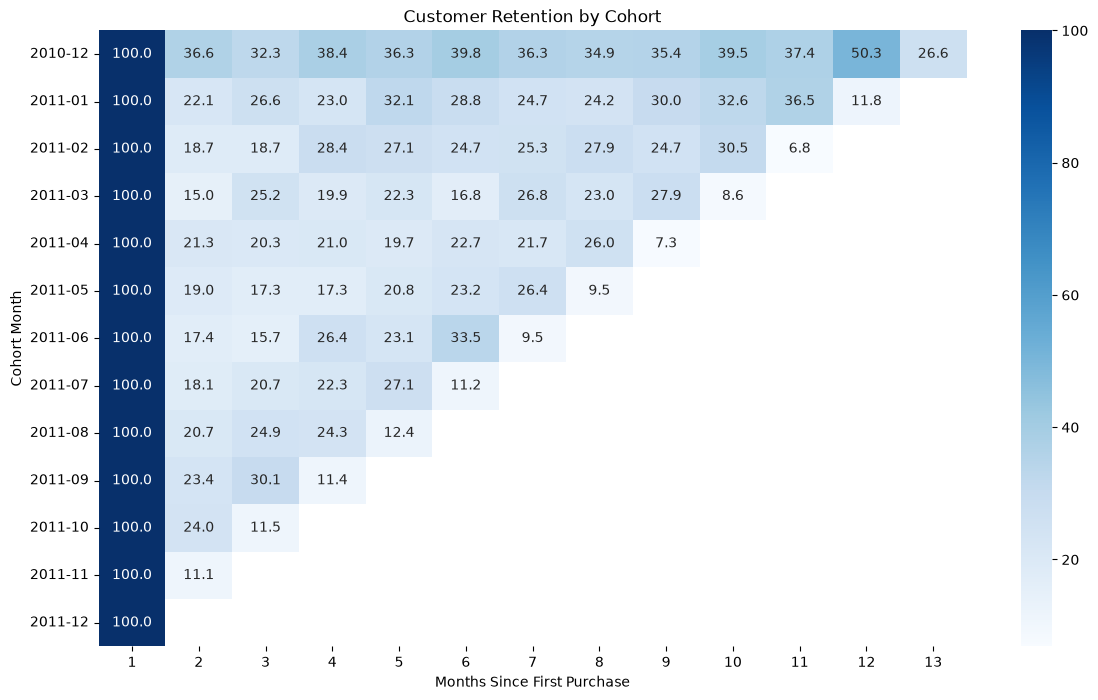

In [145]:

plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Customer Retention by Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.show()

In [146]:
retention_complete = retention_matrix.copy()

for cohort_month in retention_complete.index:
    for cohort_index in retention_complete.columns:

        purchase_month = cohort_month + (cohort_index - 1)

        if purchase_month >= pd.Period("2011-12", freq="M"):
            retention_complete.loc[cohort_month, cohort_index] = float("nan")

retention_complete.round(2)

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,NaN
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,NaN,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,NaN,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,NaN,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,NaN,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,NaN,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


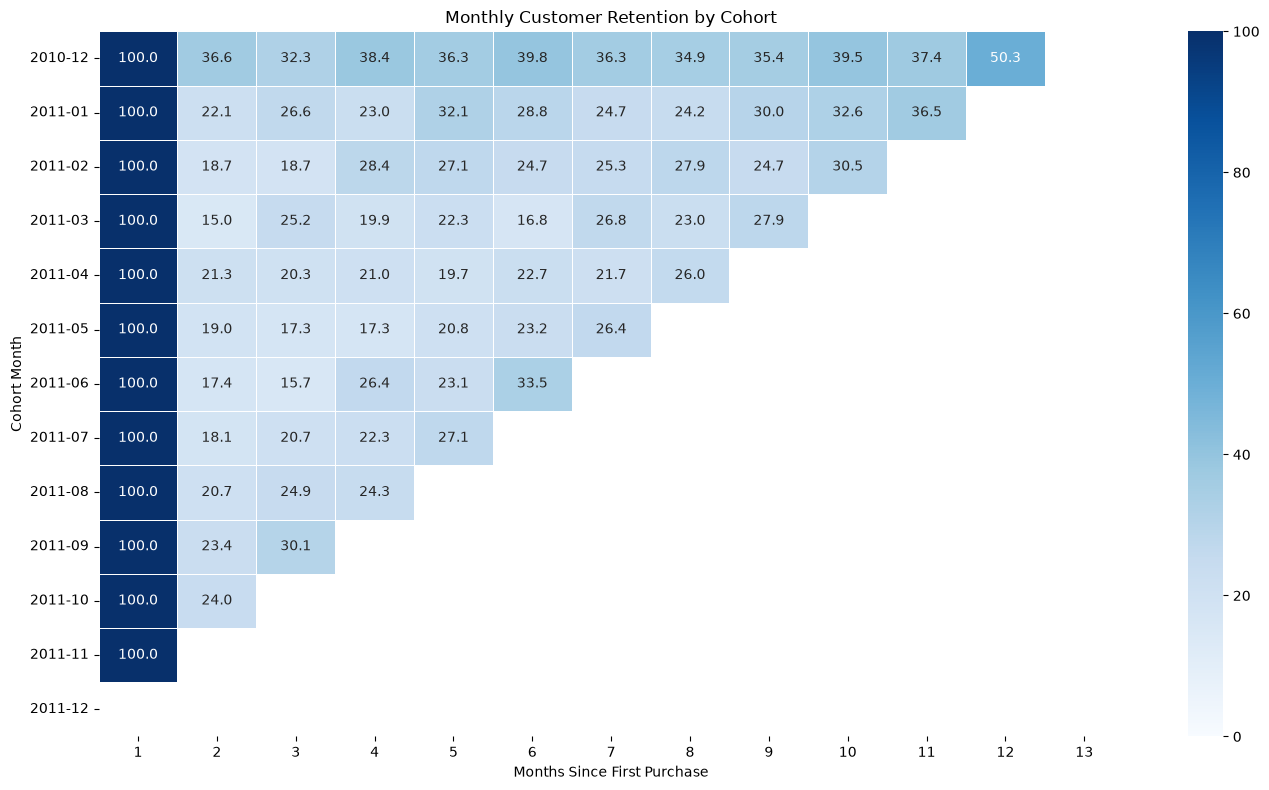

In [147]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_complete,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title("Monthly Customer Retention by Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.tight_layout()
plt.show()

In [148]:
retention_final = retention_complete.dropna(
    axis=0,
    how="all"
).dropna(
    axis=1,
    how="all"
)

retention_final

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,
2010-12,100.0,36.610169,32.316384,38.418079,36.271186,39.774011,36.271186,34.915254,35.367232,39.548023,37.401130,50.282486
2011-01,100.0,22.062350,26.618705,23.021583,32.134293,28.776978,24.700240,24.220624,29.976019,32.613909,36.450839,NaN
2011-02,100.0,18.684211,18.684211,28.421053,27.105263,24.736842,25.263158,27.894737,24.736842,30.526316,NaN,NaN
2011-03,100.0,15.044248,25.221239,19.911504,22.345133,16.814159,26.769912,23.008850,27.876106,NaN,NaN,NaN
2011-04,100.0,21.333333,20.333333,21.000000,19.666667,22.666667,21.666667,26.000000,NaN,NaN,NaN,NaN
2011-05,100.0,19.014085,17.253521,17.253521,20.774648,23.239437,26.408451,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.355372,15.702479,26.446281,23.140496,33.471074,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.085106,20.744681,22.340426,27.127660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.710059,24.852071,24.260355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


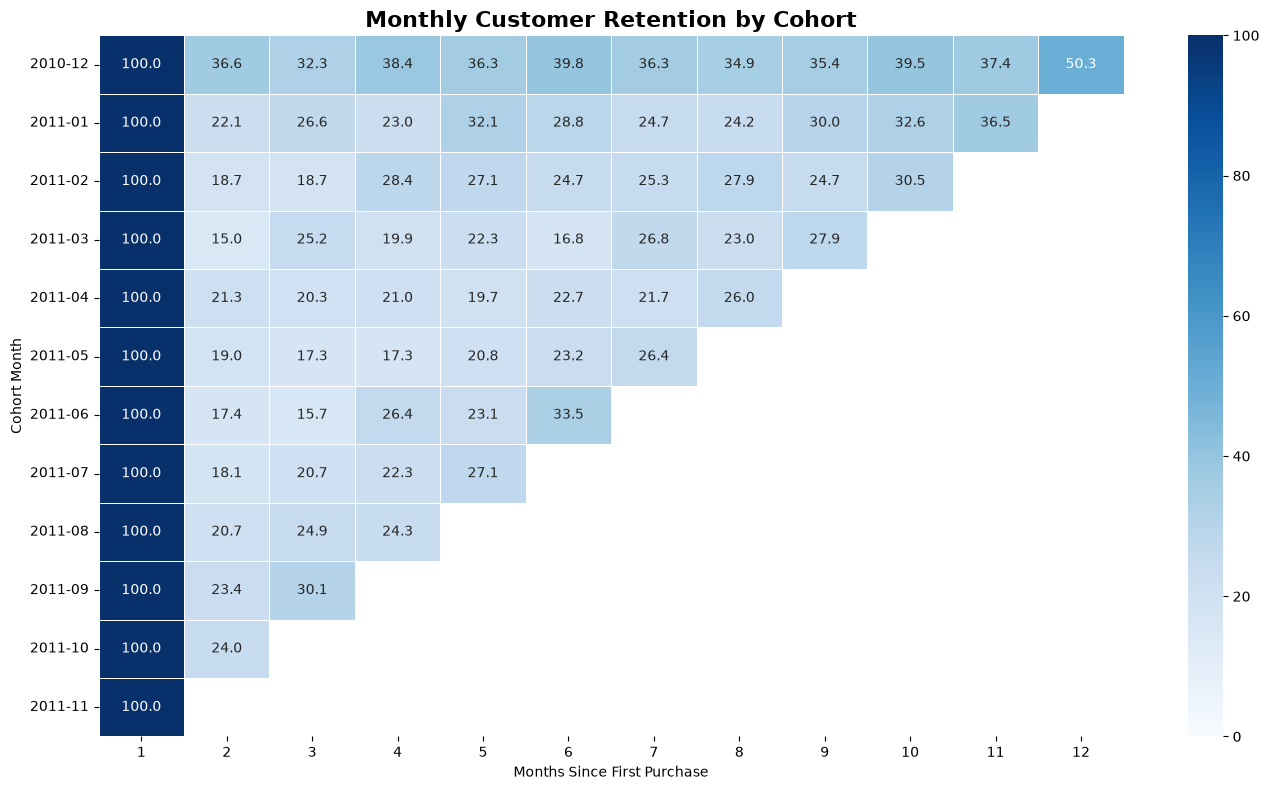

In [149]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_final,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title(
    "Monthly Customer Retention by Cohort",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.tight_layout()

plt.savefig(
    "customer_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [150]:
segment_counts = customer_summary["Segment"].value_counts()

segment_counts

Segment
Other                  1255
Potential Loyalists    1114
Hibernating             946
Champions               462
Loyal Customers         423
At Risk                 138
Name: count, dtype: int64

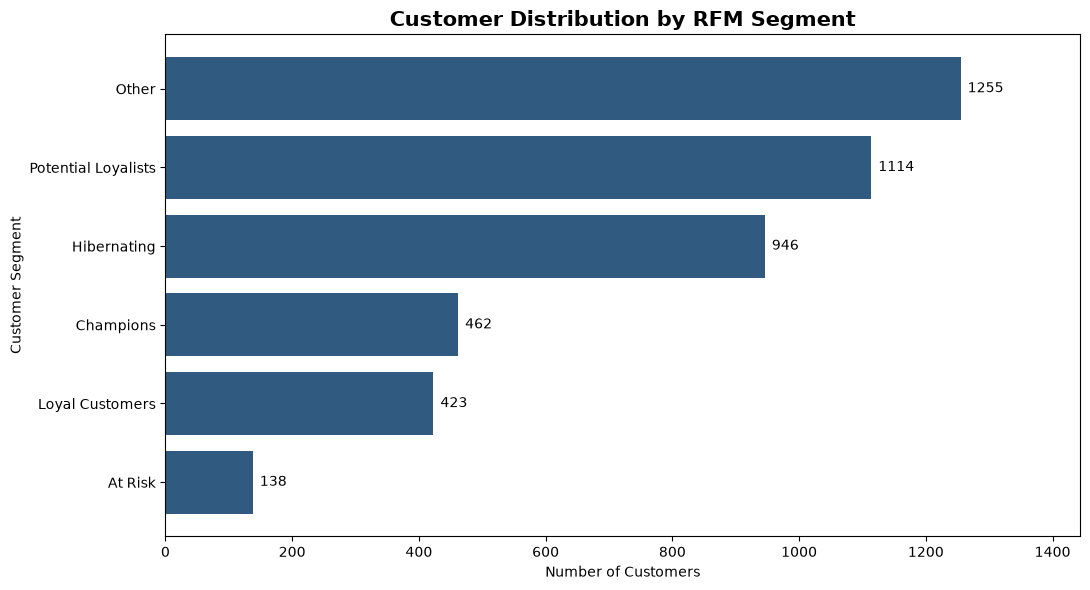

In [151]:
plt.figure(figsize=(11, 6))

bars = plt.barh(
    segment_counts.index,
    segment_counts.values,
    color="#315A80"
)

plt.bar_label(
    bars,
    padding=5
)

plt.title(
    "Customer Distribution by RFM Segment",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.gca().invert_yaxis()
plt.xlim(0, segment_counts.max() * 1.15)

plt.tight_layout()
plt.show()

In [152]:
segment_revenue = (
    customer_summary
    .groupby("Segment")["TotalSpending"]
    .sum()
    .sort_values(ascending=False)
)

segment_revenue.round(2)

Segment
Champions              4369199.09
Other                  2496527.69
Loyal Customers         739998.49
Potential Loyalists     598464.52
Hibernating             455041.62
At Risk                 252176.49
Name: TotalSpending, dtype: float64

In [153]:
segment_revenue_share = (
    segment_revenue / segment_revenue.sum()
) * 100

segment_revenue_share.round(2)

Segment
Champions              49.03
Other                  28.01
Loyal Customers         8.30
Potential Loyalists     6.72
Hibernating             5.11
At Risk                 2.83
Name: TotalSpending, dtype: float64

In [154]:
segment_comparison = pd.DataFrame({
    "Customer Share": (
        customer_summary["Segment"].value_counts(normalize=True) * 100
    ),
    "Revenue Share": segment_revenue_share
})

segment_comparison = segment_comparison.loc[
    segment_revenue_share.index
]

segment_comparison.round(2)

,Customer Share,Revenue Share
Segment,,
Champions,10.65,49.03
Other,28.93,28.01
Loyal Customers,9.75,8.30
Potential Loyalists,25.68,6.72
Hibernating,21.81,5.11
At Risk,3.18,2.83


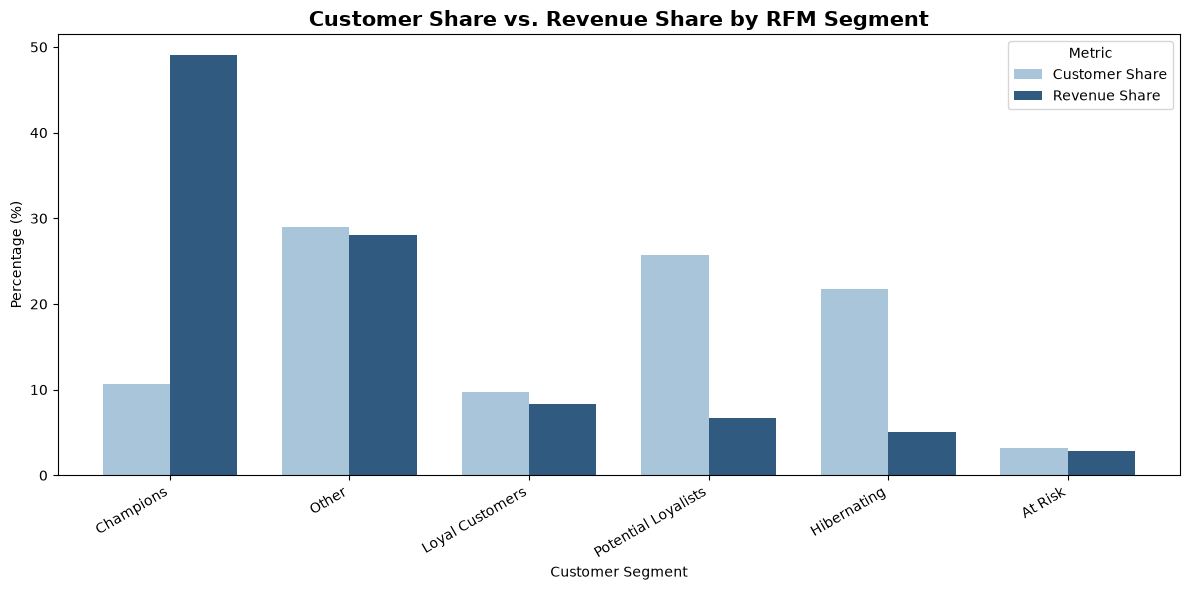

In [161]:
ax = segment_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#A8C5DA", "#315A80"],
    width=0.75
)

plt.title(
    "Customer Share vs. Revenue Share by RFM Segment",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Customer Segment")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")

plt.tight_layout()

plt.savefig(
    "customer_vs_revenue_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [157]:
segment_avg_spending = (
    customer_summary
    .groupby("Segment")["TotalSpending"]
    .mean()
    .sort_values(ascending=False)
)

segment_avg_spending.round(2)

Segment
Champions              9457.14
Other                  1989.27
At Risk                1827.37
Loyal Customers        1749.41
Potential Loyalists     537.22
Hibernating             481.02
Name: TotalSpending, dtype: float64

In [158]:
segment_spending_stats = (
    customer_summary
    .groupby("Segment")["TotalSpending"]
    .agg(["mean", "median"])
    .sort_values("mean", ascending=False)
)

segment_spending_stats.round(2)

,mean,median
Segment,,
Champions,9457.14,4119.18
Other,1989.27,1106.53
At Risk,1827.37,812.22
Loyal Customers,1749.41,1298.04
Potential Loyalists,537.22,379.96
Hibernating,481.02,296.48


## Key Findings & Business Recommendations

### 1. Revenue Concentration

Champions represent 10.65% of customers but account for
49.03% of total recorded spending.

**Recommendation:** Test targeted loyalty initiatives to
encourage retention among high-value customers.

### 2. Potential Loyalists

Potential Loyalists represent 25.68% of customers but
contribute only 6.72% of total recorded spending.

**Recommendation:** Test personalized campaigns to
encourage repeat purchases.

### 3. Inactive Customers

Hibernating customers represent 21.81% of the customer base.

**Recommendation:** Evaluate cost-effective reactivation
campaigns for inactive customers.

### 4. Early Customer Retention

Most customer cohorts recorded second-month retention
rates below 25%.

**Recommendation:** Test post-purchase engagement strategies
to encourage customers to return.

### 5. Spending Distribution

Mean spending exceeds median spending across all RFM
segments, indicating right-skewed spending distributions.

**Recommendation:** Use both mean and median when evaluating
customer value to avoid relying on averages alone.